# HalfDome halo mass calibration and paper figure

Runnable recovery of the July 2024 purple RFoF / green Tinker08-calibrated HMF figure.
The figure uses histogram counts from all 11 released HDF5 catalogs. It does not
depend on recovery of the missing original mapping tables.

The mapping below was **recovered from released pairs**, not copied from the
original `conversion_grid*.npy` files. Its provenance and independent validation
are shown explicitly. The archived notebook inputs are preserved separately.

In [1]:
from pathlib import Path
import json
import tempfile
import h5py
import numpy as np
from IPython.display import Image, display
from paper_plot import plot_release
from remapping import MassRemapping, apply_hdf5, validate_pairs

ROOT = Path.cwd()
DATA = ROOT / "data"
OUTPUT = Path.home() / "projects/halfdome/recovered-remapping-20261027/validation"
OUTPUT.mkdir(parents=True, exist_ok=True)
samples = np.load(DATA / "release_samples.npz")
print("Released seeds:", samples["seeds"].tolist())

Released seeds: [100, 102, 104, 106, 108, 110, 112, 114, 116, 118, 120]


## Reproduce the paper HMF figure

Redshift slices are 0–0.05, 1–1.05, 2–2.05, and 3–3.05. Error bars are the
standard deviation over the 11 realizations, as in the recovered inputs.
Grey curves use the installed HMF package with the HalfDome cosmology.

findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


findfont: Failed to find font weight bold for cmsy10, now using 400.


...

findfont: Failed to find font weight bold for cmti10, now using 400.


findfont: Failed to find font weight bold for cmb10, now using 400.


findfont: Failed to find font weight bold for cmss10, now using 400.


findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


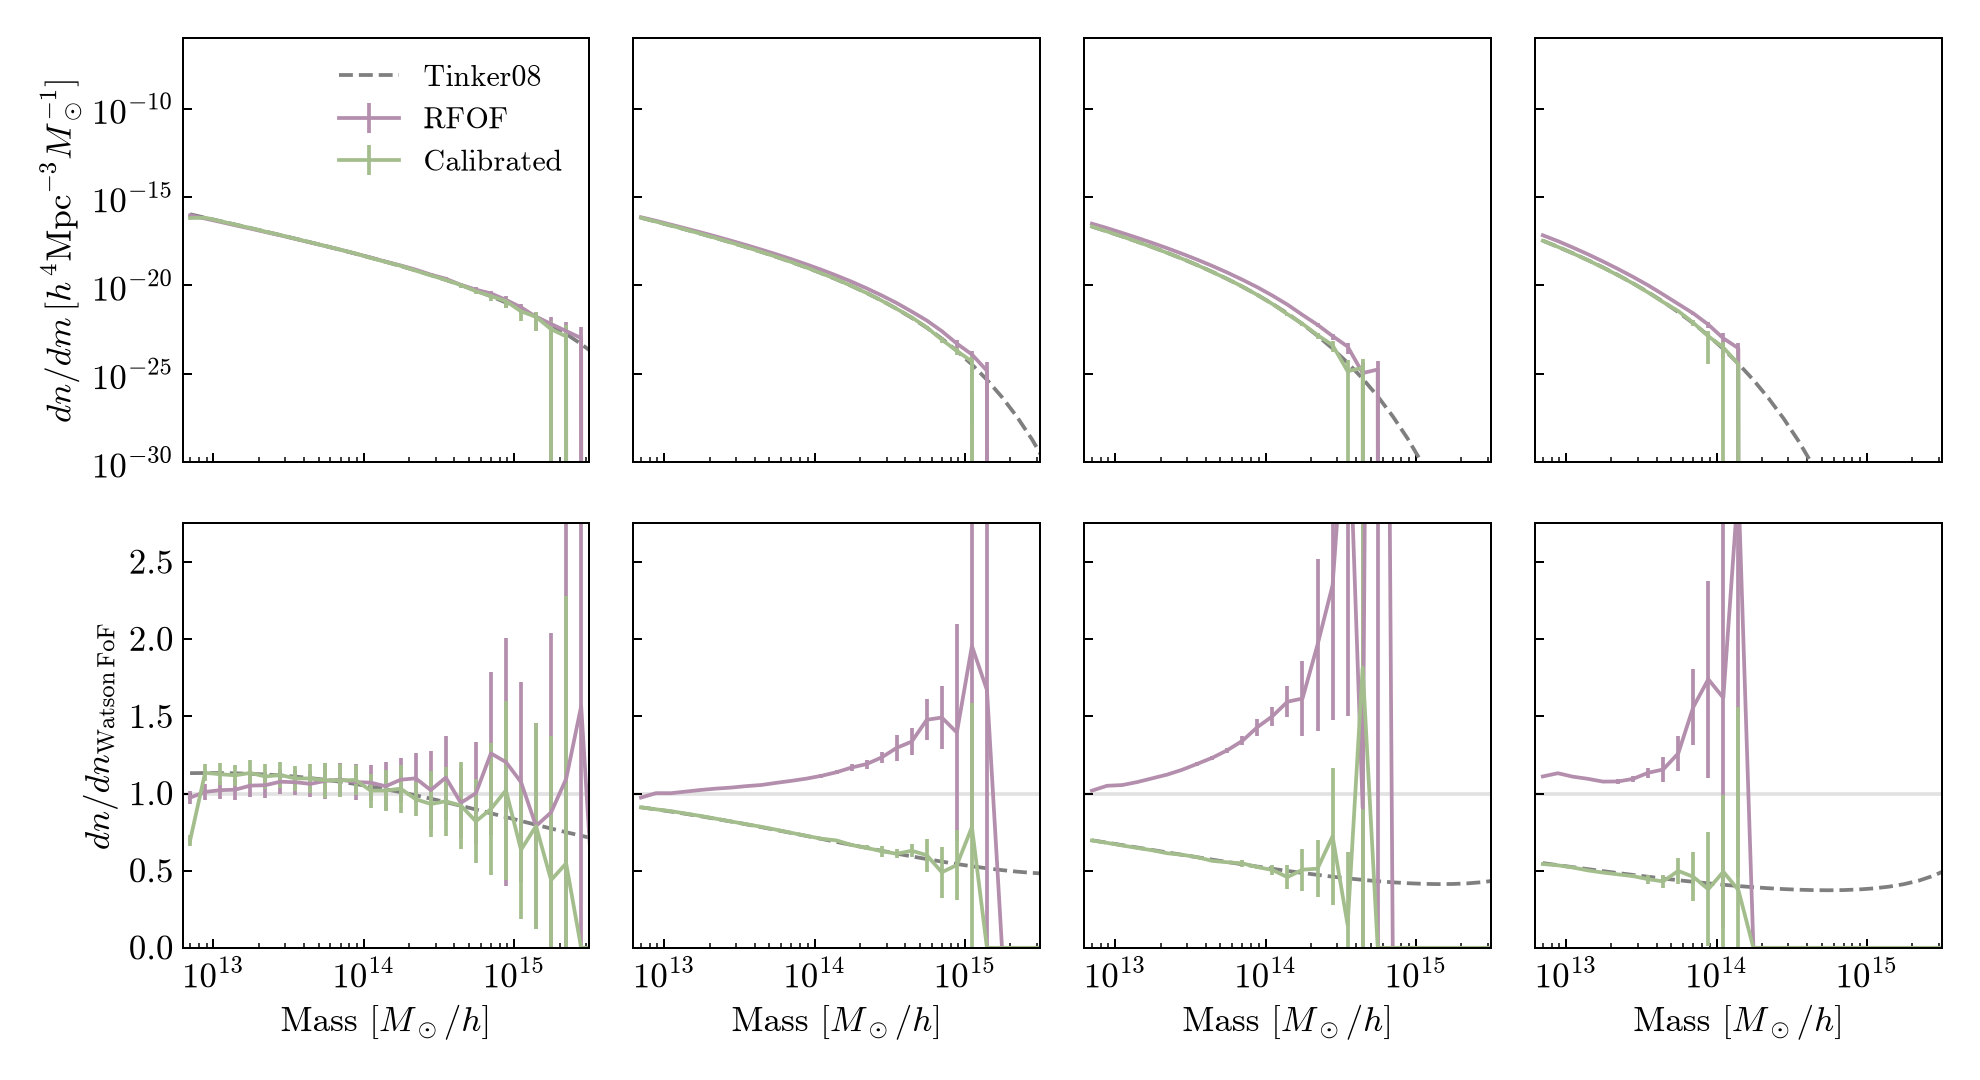

In [2]:
figure = plot_release(DATA / "release_samples.npz", OUTPUT / "reproduced-HMF")
display(Image(filename=str(figure)))

## Apply the recovered mapping

The historical formula is `log10_M200m = log10_Mrfof * (1 + correction(z, log10_Mrfof))`.
It is not a multiplicative correction to linear mass. Training excludes seed 102;
the following report uses its independent released mass pairs. Both samples are
stratified in mass and redshift and therefore emphasize rare massive halos.

The default call rejects masses above the recovery support. Setting
`allow_extrapolation=True` reproduces the historical boundary behavior, but the
unobserved high-mass continuation is not established by recovery.

In [3]:
mapping = MassRemapping.load(DATA / "recovered-grid")
final_validation = np.load(DATA / "release_final_validation.npz")
report = validate_pairs(mapping, final_validation["sample_104"])
print("Final independent check: seed 104")
print(json.dumps(report, indent=2))
print("Original table recovered:", mapping.provenance["original_grid_recovered"])

Final independent check: seed 104
{
  "rows": 76980,
  "median_absolute_relative_mass_error": 4.090212778241044e-15,
  "p99_absolute_relative_mass_error": 1.793341521997546e-11,
  "p999_absolute_relative_mass_error": 7.245900860504599e-10,
  "max_absolute_relative_mass_error": 0.0021050629953610948,
  "worst_input": [
    3.661386489868164,
    13.936741828918457
  ],
  "supported_rows": 76810,
  "supported_fraction": 0.9977916341906988,
  "supported_max_absolute_relative_mass_error": 4.741177863663349e-06
}
Original table recovered: False


In [4]:
# A small independent example within the supported mass range.
example = samples["sample_102"]
example = example[example[:, 1] < 13.3][:20]
predicted = mapping.log10_m200m(example[:, 0], example[:, 1])
relative_error = np.expm1(np.log(10) * (predicted - example[:, 2]))
print("Maximum relative mass error in example:", np.max(np.abs(relative_error)))

Maximum relative mass error in example: 2.0451063891205386e-14


## Write an aligned HDF5 mass sidecar

This demonstration uses a temporary 20-row catalog. Real inputs need `redshift`
and `log10_m_rfof` (or the historical `log10_m`) in the same row order.
The output is a new HDF5 file containing `halo_mass_m200m` in solar masses/h,
plus source, units, mapping provenance, and row-alignment attributes. Existing
catalogs are never opened for writing.

In [5]:
with tempfile.TemporaryDirectory(prefix="halfdome-example-") as temporary:
    source = Path(temporary) / "input.h5"
    destination = Path(temporary) / "m200m.h5"
    with h5py.File(source, "w") as f:
        f["redshift"] = example[:, 0]
        f["log10_m_rfof"] = example[:, 1]
    apply_hdf5(mapping, source, destination, chunk_size=7)
    with h5py.File(destination, "r") as f:
        np.testing.assert_allclose(f["halo_mass_m200m"][:], 10**predicted)
        print("Sidecar rows:", len(f["halo_mass_m200m"]))
        print("Units:", f.attrs["units"])

Sidecar rows: 20
Units: Msun/h


The source README records commands, provenance, validation limits, and the
relationship to the earlier June Watson/Aemulus scripts. This recovery provides
M200m; it does not silently substitute a different concentration prescription
for the historical M200m→M200c conversion.